In [77]:
import sounddevice as sd
import numpy as np
import matplotlib.pyplot as plt
from scipy.io.wavfile import write
import scipy.fftpack
from scipy.io import wavfile

## Part 4.1 : Example of Audio Signal Sampling
### Question 1 :
Record your own voice using the system microphone and sample it at a frequency of 8 kHz for a minimum duration of 20 seconds.

In [31]:
# --------------------------------------------------------------------
# Part 4.1 - Question 1: Recording your Own Voice and Sampling it 
# ---------------------------------------------------------------------

# --- Initial settings according to the project ---
fs = 8000  # Sampling frequency (8 kHz)
duration = 20  # Recording duration in seconds

print(f"Recording for {duration} seconds at {fs} Hz...")
print("Please speak...")

# --- 1. Audio Recording ---
# Record audio in mono (channels=1)
my_recording = sd.rec(int(duration * fs), samplerate=fs, channels=1, dtype='float64')
sd.wait()  # Wait until recording is finished
print("Recording finished.")

# Save the audio file (optional, for later use)
write('my_voice_8k.wav', fs, (my_recording * 32767).astype(np.int16))


Recording for 20 seconds at 8000 Hz...
Please speak...
Recording finished.


### Question 2 :
Plot the waveform of the sampled speech signal in the time domain.

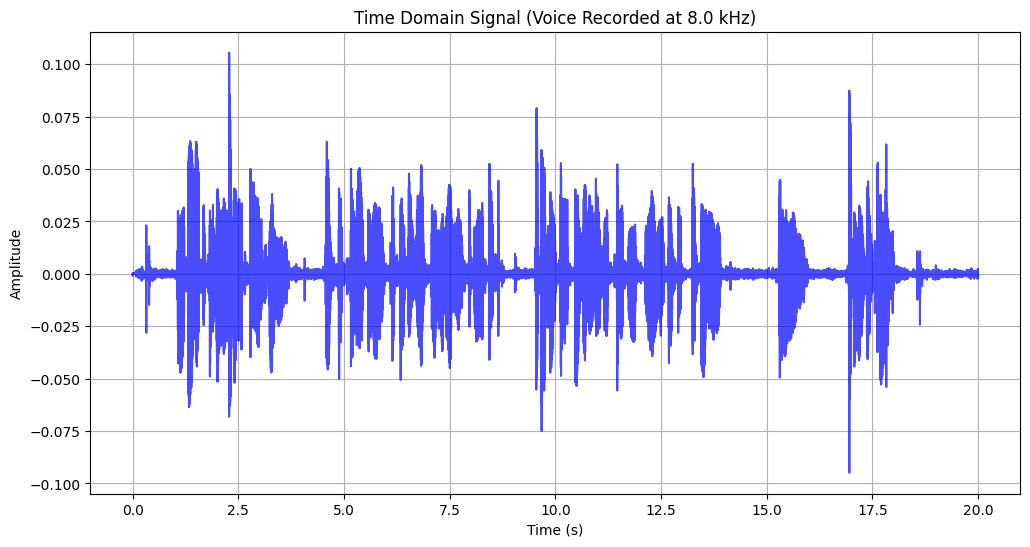

In [32]:
# ----------------------------------------------------------
# Part 4.1 - Question 2: Plot Time-Domain Waveform
# ----------------------------------------------------------

# Prepare time axis for plotting
t = np.linspace(0, duration, int(duration * fs))
signal = my_recording.flatten()
plt.figure(figsize=(12, 6))

plt.plot(t, signal, color='blue', alpha=0.7)
plt.title(f'Time Domain Signal (Voice Recorded at {fs/1000} kHz)')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True)

### Question 3
Using the Fast Fourier Transform (FFT), plot the frequency spectrum of the signal and analyze its dominant frequency band.

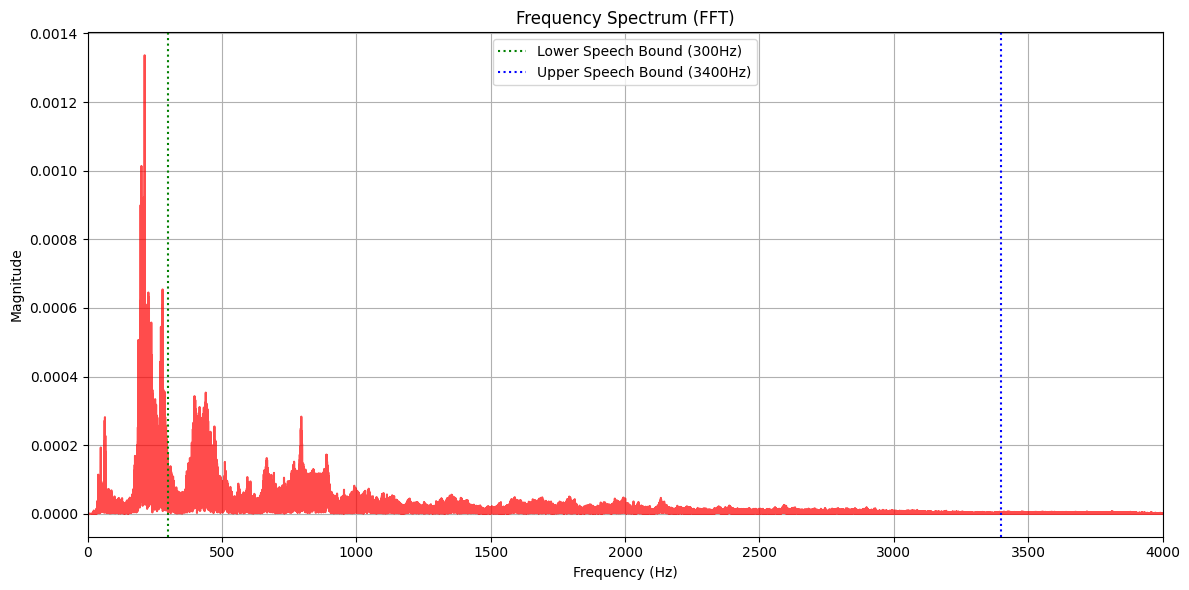

In [33]:
# ----------------------------------------------------------
# Part 4.1 - Question 3: Plot Frequency Spectrum (FFT)
# ----------------------------------------------------------

# Compute the Fast Fourier Transform
plt.figure(figsize=(12, 6))
n_samples = len(signal)
yf = scipy.fftpack.fft(signal)
xf = np.linspace(0.0, fs/2, n_samples//2)  # Frequency axis up to fs/2 (Nyquist)

# Compute amplitude spectrum (only positive frequencies)
amplitude = 2.0/n_samples * np.abs(yf[:n_samples//2])

plt.plot(xf, amplitude, color='red', alpha=0.7)
plt.title('Frequency Spectrum (FFT)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.grid(True)
plt.xlim(0, 4000)  
plt.axvline(x=300, color='green', linestyle=':', label='Lower Speech Bound (300Hz)')
plt.axvline(x=3400, color='blue', linestyle=':', label='Upper Speech Bound (3400Hz)')
plt.legend()
plt.tight_layout()
plt.show()

## Part 4.2:  Uniform Quantization and PCM
### Question 1 :
Write a function named UniformQuantizer that receives the input signal and the number of quantization bits, and outputs the quantized signal.

In [ ]:
# ----------------------------------------------------------
# Part 4.2 - Question 1: Function UniformQuantizer
# ----------------------------------------------------------
def UniformQuantizer(input_signal, n_bits):
    """
    Implementation of uniform quantization
    input_signal: input (sampled) signal
    n_bits: number of quantization bits (e.g., 8)
    """
    # 1. Determine the number of quantization levels
    L = 2**n_bits 
    
    # 2. Find the dynamic range of the signal
    v_max = np.max(np.abs(input_signal))
    v_min = -v_max  # Assume the range is symmetric around zero
    
    # 3. Calculate the step size (quantization interval)
    delta = (v_max - v_min) / L
    
    # 4. Map values to discrete levels
    # This formula moves each value to the nearest quantization level
    quantized_signal = np.round((input_signal - v_min) / delta) * delta + v_min
    
    # Ensure values do not exceed the allowable range
    quantized_signal = np.clip(quantized_signal, v_min, v_max - delta)
    
    return quantized_signal

# --- Run test on the recorded signal ---
# Assume 'signal' is the recorded signal from the previous step
n_bits = 8
quantized_voice = UniformQuantizer(signal, n_bits)

# Calculate the bit rate according to the project formula
fs = 8000
bit_rate = fs * n_bits
print(f"Bit Rate: {bit_rate/1000} kbps")  # Should be 64 kbps


Bit Rate: 64.0 kbps


### Question 2 :
Plot the original signal and the quantized signal on the same graph and compare them.

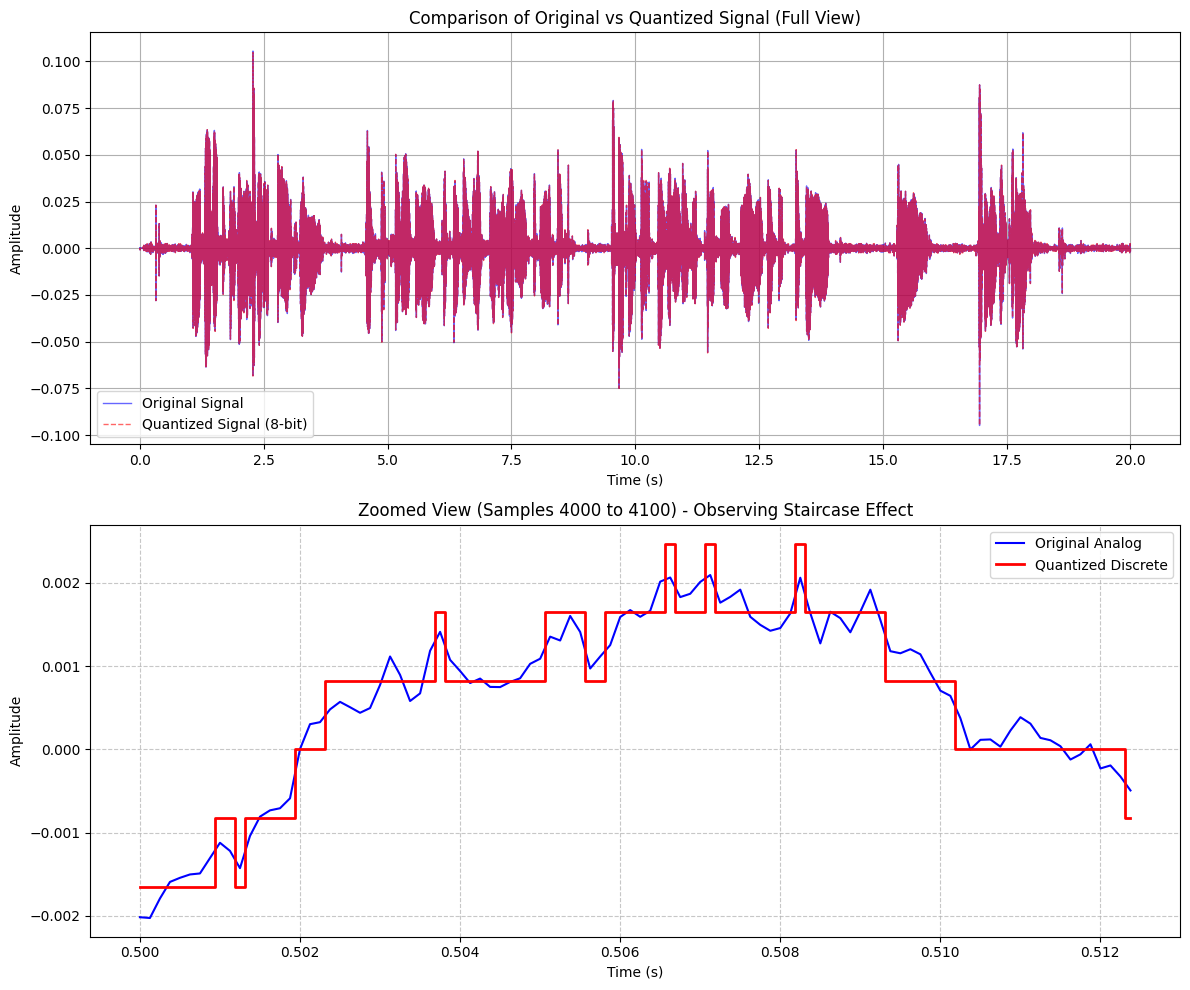

In [ ]:
# ----------------------------------------------------------
# Part 4.2 - Question 2: Original vs. Quantized Signal
# ----------------------------------------------------------

# Create the time axis
t = np.linspace(0, len(signal)/fs, len(signal))

plt.figure(figsize=(12, 10))

# --- First Plot: Full View ---
plt.subplot(2, 1, 1)
plt.plot(t, signal, label='Original Signal', color='blue', alpha=0.6, linewidth=1)
plt.plot(t, quantized_voice, label='Quantized Signal (8-bit)', color='red', alpha=0.6, linewidth=1, linestyle='--')
plt.title('Comparison of Original vs Quantized Signal (Full View)')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)

# --- Second Plot: Zoomed View ---
# Select a short interval for detailed visualization (samples 4000 to 4100)
# This allows the staircase effect of quantization to be clearly observed
start_sample = 4000
end_sample = 4100
t_zoom = t[start_sample:end_sample]
s_zoom = signal[start_sample:end_sample]
q_zoom = quantized_voice[start_sample:end_sample]

plt.subplot(2, 1, 2)
plt.plot(t_zoom, s_zoom, label='Original Analog', color='blue', linewidth=1.5)

# We use step plot to better illustrate the discrete nature of quantization
plt.step(t_zoom, q_zoom, label='Quantized Discrete', color='red', linewidth=2, where='mid')

plt.title(f'Zoomed View (Samples {start_sample} to {end_sample}) - Observing Staircase Effect')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


### Question 3 :
Compute the quantization error and plot its waveform.

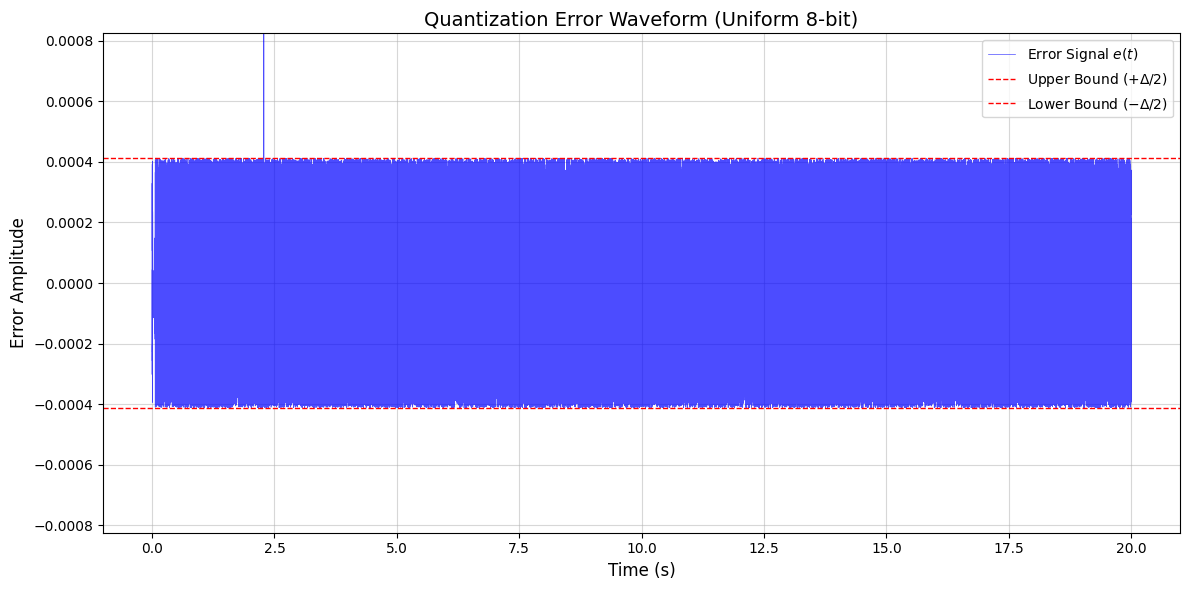

Calculated Step Size (Delta): 0.0008243999327532947
Maximum Absolute Error: 0.0008243999327532947
Theoretical Max Error (Delta/2): 0.00041219996637664735


In [ ]:
# -------------------------------------------------
# Part 4.2 - Question 3: Quantization Error 
# -------------------------------------------------

# 1. Compute the quantization error
quantization_error = signal - quantized_voice

# 2. Compute theoretical parameters (for display on the plot)
v_max = np.max(np.abs(signal))
v_min = -v_max
L = 2**n_bits
delta = (v_max - v_min) / L  # Step size (quantization interval)

# 3. Plot the error waveform
plt.figure(figsize=(12, 6))

# Plot the error signal
plt.plot(t, quantization_error, color='blue', alpha=0.7, linewidth=0.5, label='Error Signal $e(t)$')

# Plot theoretical error bounds (+Delta/2 and -Delta/2)
plt.axhline(y=delta/2, color='red', linestyle='--', linewidth=1, label=r'Upper Bound ($+\Delta/2$)')
plt.axhline(y=-delta/2, color='red', linestyle='--', linewidth=1, label=r'Lower Bound ($-\Delta/2$)')

plt.title('Quantization Error Waveform (Uniform 8-bit)', fontsize=14)
plt.xlabel('Time (s)', fontsize=12)
plt.ylabel('Error Amplitude', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, alpha=0.5)

# Limit the vertical axis to better visualize details
plt.ylim(-delta, delta) 

plt.tight_layout()
plt.show()

# Print maximum error values for reporting
max_error = np.max(np.abs(quantization_error))
print(f"Calculated Step Size (Delta): {delta}")
print(f"Maximum Absolute Error: {max_error}")
print(f"Theoretical Max Error (Delta/2): {delta/2}")


### Question 4 :
Calculate and report the Signal-to-Quantization-Noise Ratio (SNR).

In [47]:
# -------------------------------------------------
# Part 4.2 - Question 4:  SQNR Calculation 
# -------------------------------------------------

# 1. Compute the power of the original signal (P_signal)
# The average power is equal to the mean of the squared values
P_signal = np.mean(signal**2)

# 2. Compute the quantization noise power (P_noise)
# quantization_error was calculated in the previous step (signal - quantized_voice)
P_noise = np.mean(quantization_error**2)

# 3. Compute SNR in linear scale
SNR_linear = P_signal / P_noise

# 4. Compute SNR in decibels (dB)
SNR_dB = 10 * np.log10(SNR_linear)

print(f"Signal Power: {P_signal:.10f}")
print(f"Noise Power: {P_noise:.10f}")
print(f"Calculated SQNR: {SNR_dB:.2f} dB")

# 5. Compute theoretical SNR for comparison
# Theoretical formula for uniform quantization:
# SNR(dB) = 6.02*N + 1.76 + 10*log10(P_signal / Vmax^2)
v_max = np.max(np.abs(signal))
theoretical_SNR = 6.02 * n_bits + 1.76 + 10 * np.log10(P_signal / (v_max**2))
print(f"Theoretical SQNR (approx): {theoretical_SNR:.2f} dB")


Signal Power: 0.0001051931
Noise Power: 0.0000000565
Calculated SQNR: 32.70 dB
Theoretical SQNR (approx): 29.67 dB


## Part 3 : Companding 
### Question 1 
Write a function named Compressor that compresses the input speech signal based on the µ-law or A-law companding rule.

In [ ]:
# -------------------------------------------------
# Part 4.3 - Question 1:  Compressor with mu-law
# -------------------------------------------------

def Compressor(input_signal, mu=255):
    """
    Implementation of a mu-law Compressor.
    
    input_signal: normalized input signal (must be in the range [-1, 1])
    mu: compression parameter (default = 255, standard in telephony)
    """
    
    # 1. Normalize the input signal to ensure it lies in [-1, 1]
    # This step is necessary for the logarithmic formula to work properly
    v_max = np.max(np.abs(input_signal))
    x = input_signal / v_max
    
    # 2. Apply the mu-law compression formula
    # Formula: y = sign(x) * [ ln(1 + mu*|x|) / ln(1 + mu) ]
    # This increases resolution for small amplitudes
    # and compresses large amplitudes
    compressed_signal = np.sign(x) * (np.log(1 + mu * np.abs(x)) / np.log(1 + mu))
    
    return compressed_signal


# --- Test the function ---
compressed_voice = Compressor(my_recording, mu=255)


### Question 2 :
Quantize the compressed signal using 8-bit uniform quantization.

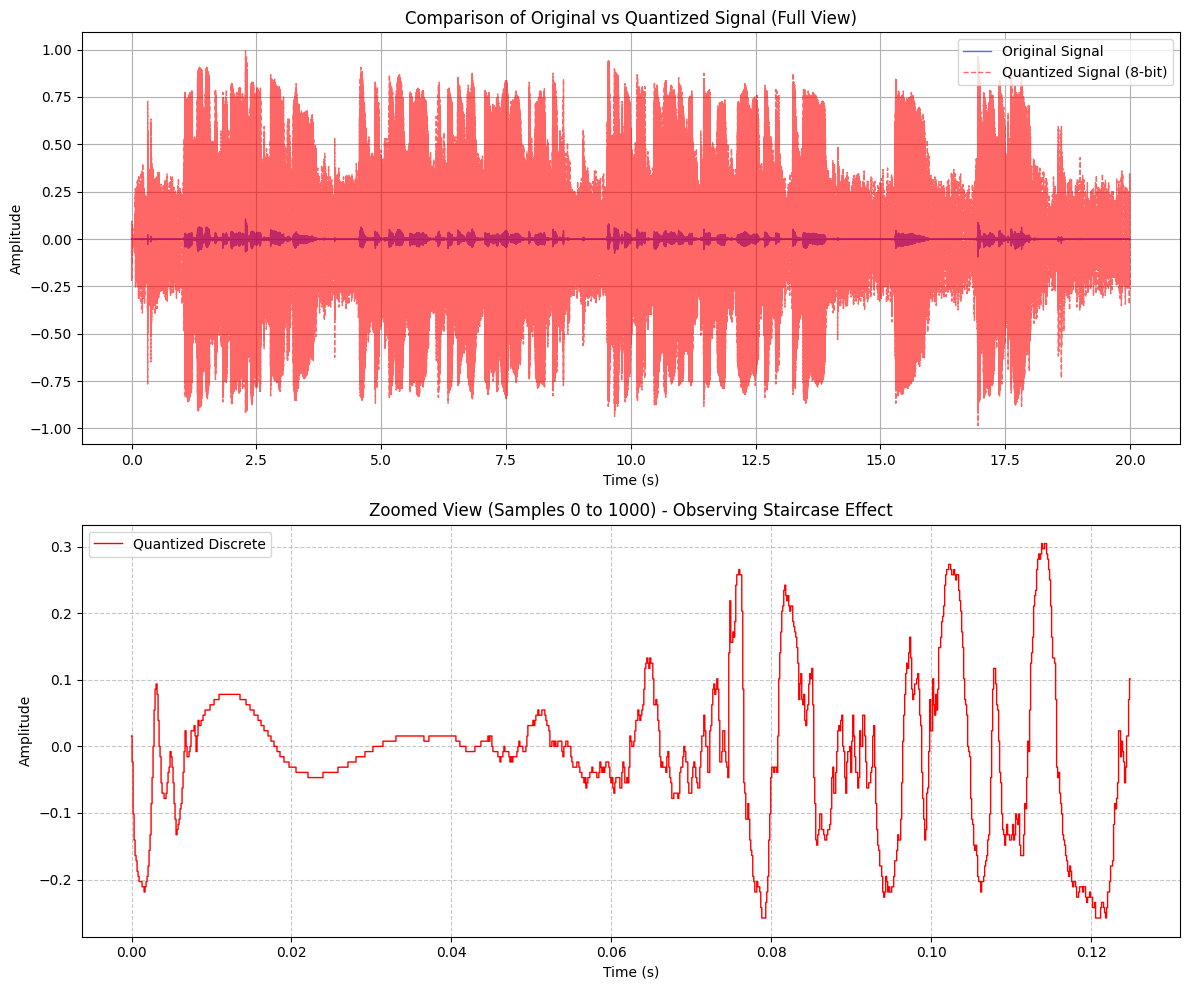

In [ ]:
# ------------------------------------------------------------
# Part 4.3 - Question 2:  Quantize the Compressed Signal 
# ------------------------------------------------------------

# 1. Compress the original signal (output will be in the range [-1, 1])
compressed_voice = Compressor(signal, mu=255)

# 2. Apply 8-bit quantization to the compressed signal
n_bits = 8
quantized_compressed_voice = UniformQuantizer(compressed_voice, n_bits)

# Create the time axis
t = np.linspace(0, len(signal)/fs, len(signal))

plt.figure(figsize=(12, 10))

# --- First Plot: Full View ---
plt.subplot(2, 1, 1)
plt.plot(t, signal, label='Original Signal', color='blue', alpha=0.6, linewidth=1)
plt.plot(t, quantized_compressed_voice, label='Quantized Signal (8-bit)', color='red', alpha=0.6, linewidth=1, linestyle='--')
plt.title('Comparison of Original vs Quantized Signal (Full View)')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)

# --- Second Plot: Zoomed View ---
# Select a short interval for detailed visualization (samples 0 to 1000)
# This helps clearly observe the staircase effect caused by quantization
start_sample = 0
end_sample = 1000
t_zoom = t[start_sample:end_sample]
q_zoom = quantized_compressed_voice[start_sample:end_sample]

plt.subplot(2, 1, 2)

# Use a step plot to better illustrate the discrete nature of quantization
plt.step(t_zoom, q_zoom, label='Quantized Discrete', color='red', linewidth=1, where='mid')

plt.title(f'Zoomed View (Samples {start_sample} to {end_sample}) - Observing Staircase Effect')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


### Question 3 :
Implement the Expander function and obtain the reconstructed signal at the receiver.

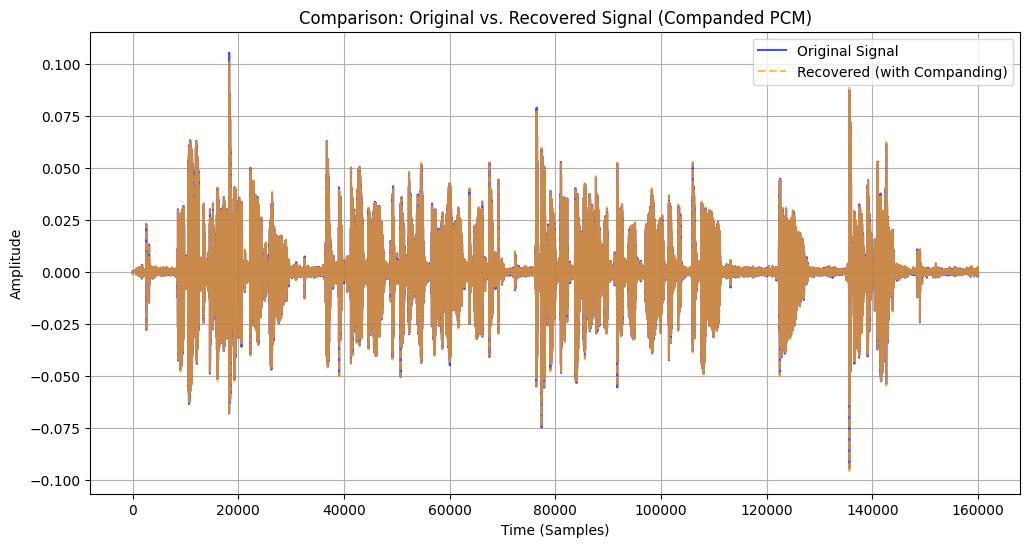

In [ ]:
# ---------------------------------------------------------------------------------
# Part 4.3 - Question 3:  Expander Function and Obtaining Reconstructed Signal
# ---------------------------------------------------------------------------------

def Expander(compressed_signal, mu=255):
    """
    Implementation of the inverse mu-law Expander.
    
    compressed_signal: compressed (and quantized) signal
    mu: compression parameter (must match the transmitter value, default = 255)
    """
    # Inverse mu-law formula:
    # x = sign(y) * (1/mu) * ((1 + mu)^|y| - 1)
    
    s = np.sign(compressed_signal)
    abs_y = np.abs(compressed_signal)
    
    # Compute the reconstructed (expanded) value
    expanded_signal = s * (1 / mu) * ((1 + mu)**abs_y - 1)
    
    return expanded_signal


# --- Run and reconstruct the signal ---
# Assumption: quantized_compressed_voice is available from the previous step
# Assumption: v_max (maximum amplitude of the original signal) is known from the first stage

# 1. Apply expansion
recovered_normalized = Expander(quantized_compressed_voice, mu=255)

# 2. Restore the original amplitude scale (Denormalization)
# Since we divided the signal by v_max in the Compressor, we must multiply here
# If v_max was not stored, the signal can remain in the normalized range [-1, 1]
v_max = np.max(np.abs(signal))  # Maximum amplitude of the original signal
recovered_signal_companded = recovered_normalized * v_max

# --- Comparative Plot ---
plt.figure(figsize=(12, 6))

# Display a short segment of the signal to observe details
plt.plot(signal, label='Original Signal', alpha=0.7, color='blue')
plt.plot(recovered_signal_companded, label='Recovered (with Companding)', alpha=0.7, color='orange', linestyle='--')

plt.title('Comparison: Original vs. Recovered Signal (Companded PCM)')
plt.xlabel('Time (Samples)')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()


### Question 4 & 5 :
Compare the reconstructed signal with companding to the case without companding, in terms of quantization error.

Compute the SNR in both cases and analyze the results.

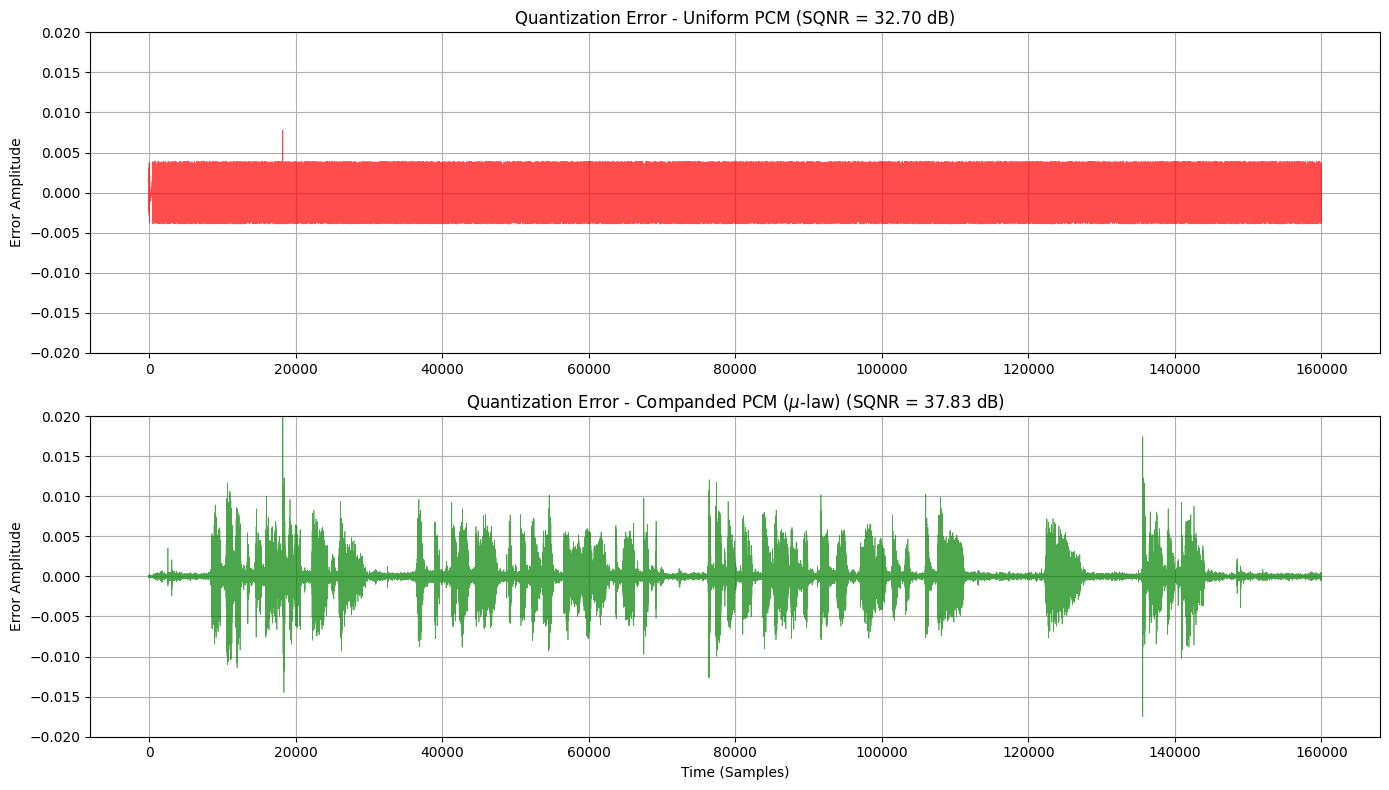

Uniform SQNR: 32.70 dB
Companded SQNR: 37.83 dB


In [74]:
# --------------------------------------------------------------
# Part 4.3 - Question 4 & 5: Quantization Error amd SQNR
# --------------------------------------------------------------

# --- (A) Case 1: Uniform Quantization (without Companding) ---
# Normalize the signal 
norm_signal = signal / np.max(np.abs(signal))
q_uniform = UniformQuantizer(norm_signal, n_bits=8)
error_uniform = norm_signal - q_uniform

# Compute SQNR for uniform quantization
P_signal = np.mean(norm_signal**2)
P_noise_uni = np.mean(error_uniform**2)
sqnr_uni_dB = 10 * np.log10(P_signal / P_noise_uni)


# --- (B) Case 2: With Companding (mu-law) ---
# 1. Compression
comp_sig = Compressor(norm_signal, mu=255)

# 2. Quantization (applied to the compressed signal)
q_comp = UniformQuantizer(comp_sig, n_bits=8)

# 3. Expansion
rec_comp = Expander(q_comp, mu=255)

# Compute the error (difference between original signal and final reconstructed signal)
error_companding = norm_signal - rec_comp

# Compute SQNR with Companding
P_noise_comp = np.mean(error_companding**2)
sqnr_comp_dB = 10 * np.log10(P_signal / P_noise_comp)


# --- (C) Plotting ---
plt.figure(figsize=(14, 8))

# 1. Plot the error signal for uniform quantization
plt.subplot(2, 1, 1)
plt.plot(error_uniform, color='red', alpha=0.7, linewidth=0.5)
plt.title(f'Quantization Error - Uniform PCM (SQNR = {sqnr_uni_dB:.2f} dB)')
plt.ylabel('Error Amplitude')
plt.ylim(-0.02, 0.02)  # Limit the axis range to better observe details
plt.grid(True)

# 2. Plot the error signal for Companding
plt.subplot(2, 1, 2)
plt.plot(error_companding, color='green', alpha=0.7, linewidth=0.5)
plt.title(f'Quantization Error - Companded PCM ($\\mu$-law) (SQNR = {sqnr_comp_dB:.2f} dB)')
plt.ylabel('Error Amplitude')
plt.xlabel('Time (Samples)')
plt.ylim(-0.02, 0.02)
plt.grid(True)

plt.tight_layout()
plt.show()

print(f"Uniform SQNR: {sqnr_uni_dB:.2f} dB")
print(f"Companded SQNR: {sqnr_comp_dB:.2f} dB")


## Part 4 : Analysis and Comparison of Results
    In this section, the performance of the PCM system is compared in two cases: uniform quantization and companding-based quantization.
### Question 1 :
Plot and compare the distribution of quantization error for both the uniform and the companded cases.

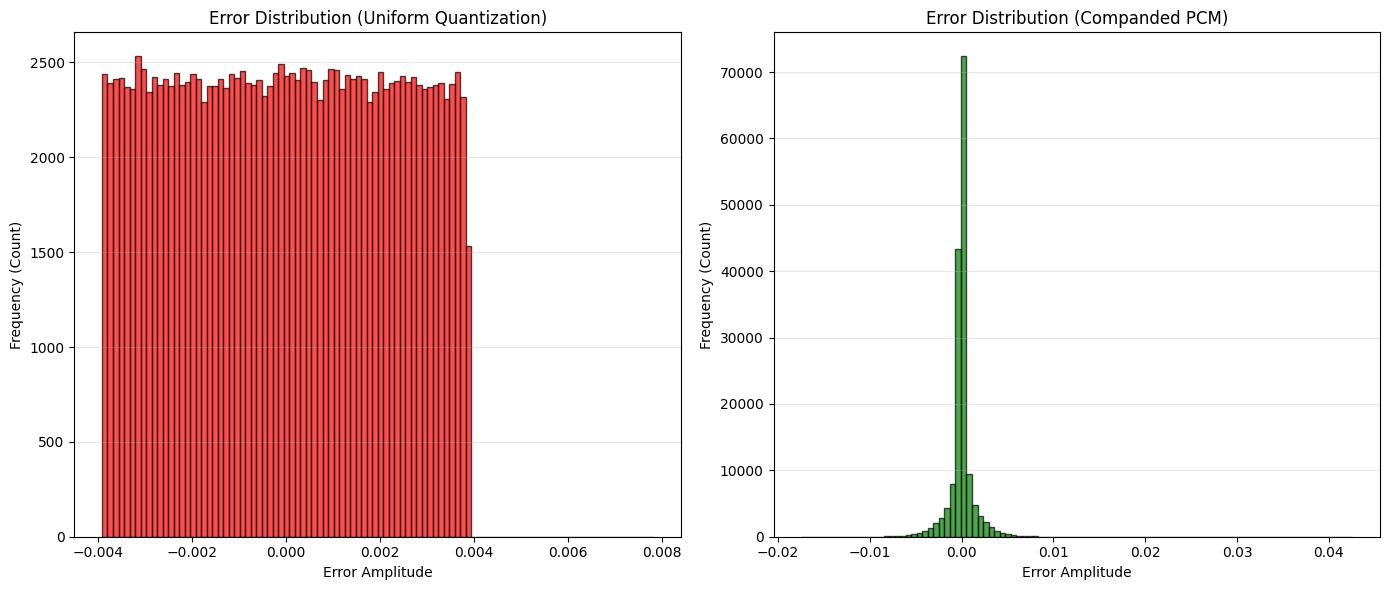

In [80]:
# --------------------------------------------------------------
# Part 4.4 - Question 1 : Distribution of Quantization Error
# --------------------------------------------------------------

plt.figure(figsize=(14, 6))

# 1. Distribution of quantization error (Uniform case)
plt.subplot(1, 2, 1)
plt.hist(error_uniform, bins=100, color='red', alpha=0.7, edgecolor='black')
plt.title('Error Distribution (Uniform Quantization)')
plt.xlabel('Error Amplitude')
plt.ylabel('Frequency (Count)')
plt.grid(axis='y', alpha=0.3)

# 2. Distribution of quantization error (Companding case)
plt.subplot(1, 2, 2)
plt.hist(error_companding, bins=100, color='green', alpha=0.7, edgecolor='black')
plt.title('Error Distribution (Companded PCM)')
plt.xlabel('Error Amplitude')
plt.ylabel('Frequency (Count)')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Question 3 :
Compare and analyze the reconstructed signals in both cases from an auditory perspective (sound quality).

In [81]:
# --------------------------------------------------------------
# Part 4.4 - Question 3 : Saving the Reconstructed Signals 
# --------------------------------------------------------------

def save_voice(filename, data, fs):
    """
    Save the signal as a standard WAV file
    """
    # 1. Normalize again to ensure the signal stays within the valid range
    # (divide by maximum value to prevent clipping)
    data_normalized = data / np.max(np.abs(data))
    
    # 2. Convert to 16-bit PCM format (required for WAV files)
    data_int16 = (data_normalized * 32767).astype(np.int16)
    
    # 3. Write the file
    wavfile.write(filename, fs, data_int16)
    print(f"File saved: {filename}")

# Save the reconstructed signal in the uniform case
save_voice("reconstructed_uniform.wav", q_uniform, fs)

# Save the reconstructed signal in the non-uniform (Companded) case
save_voice("reconstructed_companded.wav", recovered_signal_companded, fs)


File saved: reconstructed_uniform.wav
File saved: reconstructed_companded.wav
